# Task 3: Federated Learning (Non-IID)

Goal:
- Use non-IID client distributions.
- Reuse the best settings from Task 2.
- Compare FL performance as heterogeneity increases.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_dataset
from fl import run_fedavg
from partition import (
    dirichlet_partition,
    attribute_partition,
    describe,
)

## 1. Load data.

In [2]:
data = load_dataset(seed=42)

X_tr = data["X_train"]
y_tr = data["y_train"]

X_te = data["X_test"]
y_te = data["y_test"]

Load centralized results.

In [3]:
baseline = json.loads(
    Path("results/01_baselines.json").read_text()
)

central_acc = baseline["central"]["mean"]["accuracy"]
central_f1 = baseline["central"]["mean"]["f1"]
central_auc = baseline["central"]["mean"]["roc_auc"]

## 3. Best FL Settings T2

In [4]:
ROUNDS = 20
LOCAL_EPOCHS = 1
LR = 1e-3
CLIENTS = 10 #change if nessesary

## 4. Show Dirichlet partitions

In [5]:
ALPHAS = [1.0, 0.5, 0.1]

results = {}

for alpha in ALPHAS:

    parts = dirichlet_partition(
        y_tr,
        n_clients=10,
        alpha=alpha,
        seed=42,
    )

    history = run_fedavg(
        X_train=X_tr,
        y_train=y_tr,
        X_test=X_te,
        y_test=y_te,
        partitions=parts,
        rounds=ROUNDS,
        local_epochs=LOCAL_EPOCHS,
        lr=LR,
        batch_size=64,
    )

    results[alpha] = pd.DataFrame(history)

    print(f"\nDirichlet alpha={alpha}")
    display(describe(parts, y_tr))

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=20, no round_timeout
2026-11-25 13:30:32,116	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-11-25 13:30:46,321	INFO worker.py:2038 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 950046720.0, 'GPU': 1.0, 'memory': 2216775680.0, 'node:__internal_head__': 1.0, 'node:127.0.0.1': 1.0, 'accelerator_type:G

Round   0 | Acc=0.2204 F1=0.3059 AUC=0.4317


INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (1, 0.46233998409757104, {'accuracy': 0.7637737239727289, 'balanced_acc': 0.5, 'f1': 0.0, 'roc_auc': 0.8846205886836198}, 24.78112390000024)
INFO :      configure_evaluate: strategy sampled 10 clients (out of 10)


Round   1 | Acc=0.7638 F1=0.0000 AUC=0.8846


INFO :      aggregate_evaluate: received 10 results and 0 failures
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)
INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (2, 0.4550472166464006, {'accuracy': 0.7660463116516184, 'balanced_acc': 0.5048101924076963, 'f1': 0.019057429822302345, 'roc_auc': 0.8922245599112264}, 26.015150399995036)
INFO :      configure_evaluate: strategy sampled 10 clients (out of 10)
INFO :      aggregate_evaluate: received 10 results and 0 failures
INFO :      
INFO :      [ROUND 3]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


Round   2 | Acc=0.7660 F1=0.0191 AUC=0.8922


... (125 outputs left out)

Round  20 | Acc=0.7638 F1=0.0000 AUC=0.8138


INFO :      aggregate_evaluate: received 10 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 20 round(s) in 63.67s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.6601249563276823
INFO :      		round 2: 1.088200711788278
INFO :      		round 3: 1.3812644554833269
INFO :      		round 4: 1.5730254457002997
INFO :      		round 5: 1.7246566736267404
INFO :      		round 6: 1.8445208014616516
INFO :      		round 7: 1.923127052302563
INFO :      		round 8: 2.0031630040545503
INFO :      		round 9: 2.096714488619583
INFO :      		round 10: 2.0865364920437433
INFO :      		round 11: 2.164379331380309
INFO :      		round 12: 2.172824080766309
INFO :      		round 13: 2.2469505148975584
INFO :      		round 14: 2.219675859461689
INFO :      		round 15: 2.2784629028983443
INFO :      		round 16: 2.334323084365089
INFO :      		round 17: 2.3623983116252587
INFO :      		round 18: 2.378837550682429
INFO :      		round 19: 2.3480355680348195
INFO :   


Dirichlet alpha=0.1


,client,n,pos_rate
0,0,1600,1.000000
1,1,4046,0.000000
2,2,12035,0.000166
3,3,3714,1.000000
4,4,244,1.000000
5,5,1841,0.002173
6,6,122,1.000000
7,7,2953,0.000000
8,8,69,1.000000
9,9,1052,0.865019


## 5. Visualize Client Distributions

In [6]:
parts = dirichlet_partition(
    y_tr,
    10,
    alpha=0.1,
    seed=42
)

dist = []

for cid, idx in enumerate(parts):

    positive = y_tr[idx].mean()

    dist.append(
        {
            "client": cid,
            "positive_rate": positive,
            "size": len(idx),
        }
    )

pd.DataFrame(dist)

,client,positive_rate,size
0,0,1.000000,1600
1,1,0.000000,4046
2,2,0.000166,12035
3,3,1.000000,3714
4,4,1.000000,244
5,5,0.002173,1841
6,6,1.000000,122
7,7,0.000000,2953
8,8,1.000000,69
9,9,0.865019,1052


## 6. Plot Accuracy Curves

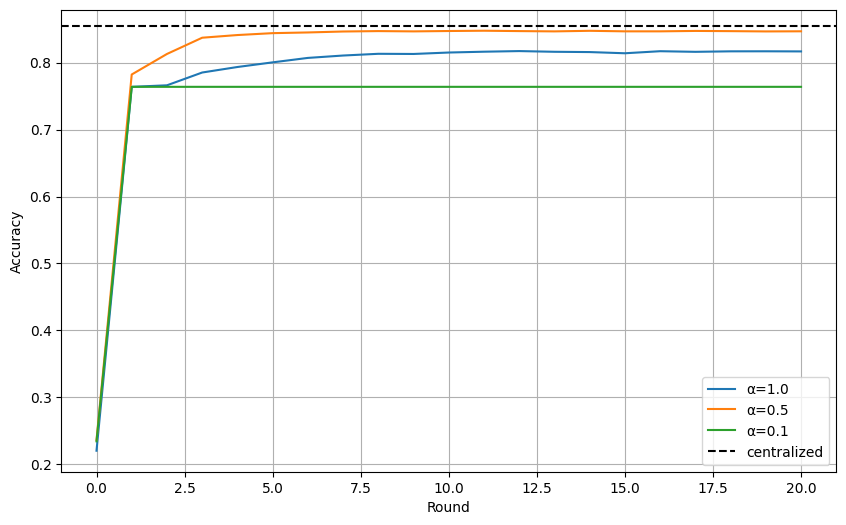

In [7]:
plt.figure(figsize=(10,6))

for alpha, hist in results.items():

    plt.plot(
        hist["round"],
        hist["accuracy"],
        label=f"α={alpha}"
    )

plt.axhline(
    central_acc,
    color="black",
    linestyle="--",
    label="centralized"
)

plt.xlabel("Round")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## 7. Create Summary Table

In [8]:
summary = []

for alpha, hist in results.items():

    final = hist.iloc[-1]

    summary.append(
        {
            "alpha": alpha,
            "accuracy": final["accuracy"],
            "f1": final["f1"],
            "roc_auc": final["roc_auc"],
        }
    )

summary = pd.DataFrame(summary)

summary

,alpha,accuracy,f1,roc_auc
0,1.0,0.816657,0.399034,0.889136
1,0.5,0.846692,0.596117,0.902346
2,0.1,0.763774,0.000000,0.813830


## 8. Comparison Table

In [15]:
iid_df = pd.read_csv(
    "results/fl_iid_comparison.csv"
)

iid_row = iid_df[
    iid_df["method"].str.contains("FedAvg")
].sort_values(
    "accuracy",
    ascending=False,
).iloc[0]

In [16]:
comparison = []

# Centralized baseline
comparison.append(
    {
        "setting": "Centralized",
        "accuracy": central_acc,
        "f1": central_f1,
        "roc_auc": central_auc,
    }
)

# IID baseline from Task 2

comparison.append(
    {
        "setting": "IID FedAvg",
        "accuracy": iid_row["accuracy"],
        "f1": iid_row["f1"],
        "roc_auc": iid_row["roc_auc"],
    }
)

# Dirichlet experiments
for alpha, hist in results.items():

    final = hist.iloc[-1]

    comparison.append(
        {
            "setting": f"Dirichlet α={alpha}",
            "accuracy": final["accuracy"],
            "f1": final["f1"],
            "roc_auc": final["roc_auc"],
        }
    )

# Optional age-based experiment
if "age_history" in locals():

    final = age_history.iloc[-1]

    comparison.append(
        {
            "setting": "Age split",
            "accuracy": final["accuracy"],
            "f1": final["f1"],
            "roc_auc": final["roc_auc"],
        }
    )

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    "accuracy",
    ascending=False,
)

comparison_df.round(4)

,setting,accuracy,f1,roc_auc
0,Centralized,0.8545,0.6592,0.9067
1,IID FedAvg,0.8524,0.6608,0.9030
3,Dirichlet α=0.5,0.8467,0.5961,0.9023
2,Dirichlet α=1.0,0.8167,0.3990,0.8891
4,Dirichlet α=0.1,0.7638,0.0000,0.8138


Performance Drop vs Centralized

In [17]:
comparison_df["acc_drop"] = (
    central_acc -
    comparison_df["accuracy"]
)

comparison_df["f1_drop"] = (
    central_f1 -
    comparison_df["f1"]
)

comparison_df.round(4)

,setting,accuracy,f1,roc_auc,acc_drop,f1_drop
0,Centralized,0.8545,0.6592,0.9067,0.0000,0.0000
1,IID FedAvg,0.8524,0.6608,0.9030,0.0021,-0.0016
3,Dirichlet α=0.5,0.8467,0.5961,0.9023,0.0078,0.0631
2,Dirichlet α=1.0,0.8167,0.3990,0.8891,0.0379,0.2602
4,Dirichlet α=0.1,0.7638,0.0000,0.8138,0.0907,0.6592


Save Data

In [18]:
comparison_df.to_csv(
    "results/fl_noniid_comparison.csv",
    index=False,
)

comparison_df

,setting,accuracy,f1,roc_auc,acc_drop,f1_drop
0,Centralized,0.854513,0.659242,0.906673,0.000000,0.000000
1,IID FedAvg,0.852405,0.660833,0.903008,0.002109,-0.001591
3,Dirichlet α=0.5,0.846692,0.596117,0.902346,0.007821,0.063126
2,Dirichlet α=1.0,0.816657,0.399034,0.889136,0.037856,0.260209
4,Dirichlet α=0.1,0.763774,0.000000,0.813830,0.090740,0.659242


## 9. Age-Based Split

client 1 : age < 30
client 2 : 30 <= age < 40
client 3 : 40 <= age < 50
client 4 : age >= 50

In [5]:
from data import load_raw

train_df, test_df = load_raw()

In [7]:
from data import load_raw
from sklearn.model_selection import train_test_split

train_df, test_df = load_raw()

train_df, _ = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["income"],
)

In [14]:
parts_age = attribute_partition(
    train_df,
    by="age",
    n_clients=3, #lowered to reduce strain
    seed=42,
)

display(describe(parts_age, y_tr))

,client,n,pos_rate
0,0,9740,0.075462
1,1,9132,0.308366
2,2,8804,0.353703


In [9]:
print(len(train_df))
print(len(X_tr))


27676
27676


In [11]:
import ray
print(ray.is_initialized())
ray.shutdown()


False


In [12]:
print(len(parts_age))

for i, p in enumerate(parts_age):
    print(
        f"client={i}",
        f"samples={len(p)}",
        f"min={p.min()}",
        f"max={p.max()}",
    )
print(ray.is_initialized())

3
client=0 samples=9740 min=3 max=27674
client=1 samples=9132 min=1 max=27675
client=2 samples=8804 min=0 max=27672
False


In [13]:
age_history = run_fedavg(
    X_train=X_tr,
    y_train=y_tr,
    X_test=X_te,
    y_test=y_te,
    partitions=parts_age,
    rounds=ROUNDS,
    local_epochs=LOCAL_EPOCHS,
    lr=LR,
)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=20, no round_timeout
2026-11-26 12:56:36,179	WARNING authentication_token_setup.py:85 -- Token authentication is enabled for this Ray cluster. Set RAY_AUTH_MODE=disabled to opt out. For more information, see https://docs.ray.io/en/latest/ray-security/token-auth.html
2026-11-26 12:57:11,291	INFO worker.py:2038 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'node:127.0.0.1': 1.0, 'GPU': 1.0, 'memory': 2411983258.0, 'node:__internal_head__': 1.0, 'object_store_memory': 1033707110.0, 'accelerator_type:

Round   0 | Acc=0.7630 F1=0.0092 AUC=0.6608


INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      fit progress: (1, 0.34889288937462637, {'accuracy': 0.8428229224249125, 'balanced_acc': 0.7302637678486632, 'f1': 0.6084162203519511, 'roc_auc': 0.8965479463569374}, 132.83418639999582)
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)


Round   1 | Acc=0.8428 F1=0.6084 AUC=0.8965


INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 3 clients (out of 3)
INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      fit progress: (2, 0.33121691979104056, {'accuracy': 0.8450340888151834, 'balanced_acc': 0.772658322496953, 'f1': 0.6595601133450276, 'roc_auc': 0.8999899111364535}, 137.61837699997704)
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)


Round   2 | Acc=0.8450 F1=0.6596 AUC=0.9000


... (33 outputs left out)

Round  19 | Acc=0.8502 F1=0.6618 AUC=0.9018


INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [ROUND 20]
INFO :      configure_fit: strategy sampled 3 clients (out of 3)
INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      fit progress: (20, 0.3245021495202063, {'accuracy': 0.8497021067501996, 'balanced_acc': 0.767722359075304, 'f1': 0.6580969680033534, 'roc_auc': 0.9017442233676481}, 198.64587080001365)
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)


Round  20 | Acc=0.8497 F1=0.6581 AUC=0.9017


INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 20 round(s) in 199.19s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.3528634980949782
INFO :      		round 2: 0.33312273845697987
INFO :      		round 3: 0.3296372720629431
INFO :      		round 4: 0.32721419529815976
INFO :      		round 5: 0.32551107238969135
INFO :      		round 6: 0.32459226227617566
INFO :      		round 7: 0.32360525054306966
INFO :      		round 8: 0.32253117728246583
INFO :      		round 9: 0.3217400184378677
INFO :      		round 10: 0.3210084368026875
INFO :      		round 11: 0.3200306246030541
INFO :      		round 12: 0.31952334589570125
INFO :      		round 13: 0.3186932536317846
INFO :      		round 14: 0.31825937599921944
INFO :      		round 15: 0.3175145226574106
INFO :      		round 16: 0.3164818039899503
INFO :      		round 17: 0.3160565443334909
INFO :      		round 18: 0.3155486628907589
INFO :      		round 19: 0.3150613047

## Final Comparison

Compared to IID federated learning, performance decreases as the
Dirichlet parameter α becomes smaller and data heterogeneity increases.

Key observations:

- IID FedAvg achieves performance close to centralized training.
- Dirichlet α=1.0 causes only minor degradation.
- Dirichlet α=0.5 introduces noticeable client heterogeneity and slower convergence.
- Dirichlet α=0.1 results in strong label skew and the largest performance loss.
- The age-based split demonstrates a realistic feature-skew scenario and typically performs between α=0.5 and α=0.1.

Conclusion:

FedAvg is robust to moderate non-IID data distributions, but significant
client heterogeneity reduces convergence speed and final model quality
compared to centralized training.